<a href="https://colab.research.google.com/github/Mithun-J/casesstudy-preprocessing/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_mithun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name: Mithub J
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary
display(df.shape)
display(df.dtypes)
display(df.isnull().sum())
display((df.isnull().sum() / len(df)) * 100)
print("")


missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})
display(missing_summary)
print("")


# Check dataset memory usage
print("Memory usage:", df.memory_usage(deep=True).sum(), "bytes")

(48895, 16)

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


,0
id,0.000000
name,0.032723
host_id,0.000000
host_name,0.042949
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000


,Missing Values,Missing Percentage
id,0,0.000000
name,16,0.032723
host_id,0,0.000000
host_name,21,0.042949
neighbourhood_group,0,0.000000
neighbourhood,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
room_type,0,0.000000
price,0,0.000000



Memory usage: 22369762 bytes


In [ ]:
# TODO: Check for values that are technically present but don't make real-world sense

# Check numeric columns
display(df.describe())

# Check listings with zero or negative prices
print("Invalid prices:", (df["price"] <= 0).sum())

# Check minimum-night requirements exceeding three years
print("Minimum nights greater than 1095:",(df["minimum_nights"] > 1095).sum())

# Check negative minimum-night requirements
print("Invalid minimum nights:",(df["minimum_nights"] <= 0).sum())

# Check availability outside the valid range of 0–365 days
print("Invalid availability:",((df["availability_365"] < 0) |(df["availability_365"] > 365)).sum())

# Check negative review counts

print("Negative review counts:",(df["number_of_reviews"] < 0).sum())

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


Invalid prices: 11
Minimum nights greater than 1095: 1
Invalid minimum nights: 0
Invalid availability: 0
Negative review counts: 0


In [ ]:
# TODO: duplicate check
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

Rows: 48895
Columns: 16
Duplicate rows: 0


**Written notes — what did you find, and what looks suspicious?**

The dataset contains 48,895 rows and 16 columns. Some columns have missing values, particularly `reviews_per_month` and `last_review`. The numerical summary shows suspicious values, including zero-price listings and a maximum minimum-stay requirement of 1,250 nights. The maximum price is $10,000, which could represent a genuine expensive listing and should not automatically be treated as an error. Availability values range from 0 to 365 days, which is valid. I also checked for negative prices, unrealistic minimum-night requirements, invalid availability, negative review counts, and duplicate records. These checks help identify potential data-quality issues that need further investigation before cleaning the dataset.


---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# TODO: Investigate missingness pattern(s) across columns

display(df.isnull().sum())
display(df[df["reviews_per_month"].isnull()][
    ["number_of_reviews", "last_review"]
])

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


,number_of_reviews,last_review
2,0,NaN
19,0,NaN
26,0,NaN
36,0,NaN
38,0,NaN
...,...,...
48890,0,NaN
48891,0,NaN
48892,0,NaN
48893,0,NaN


**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

The missing values in `last_review` and `reviews_per_month` are likely MNAR because listings with no reviews have no last review date and no monthly review history. The missingness is related to the listing's review activity. Therefore, I replaced missing values in `reviews_per_month` with 0 because listings without reviews have no recorded monthly reviews.

The missingness in `last_review` is also explainable by `number_of_reviews`: listings with zero reviews have no last review date. This indicates a relationship between the missing values and another column in the dataset.


In [ ]:
# TODO: Apply your chosen treatment(s)

df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

display(df.isnull().sum())
display(df[["name", "host_name", "number_of_reviews", "last_review", "reviews_per_month"]].head())

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


,name,host_name,number_of_reviews,last_review,reviews_per_month
0,Clean & quiet apt home by the park,John,9,2018-10-19,0.21
1,Skylit Midtown Castle,Jennifer,45,2019-05-21,0.38
2,THE VILLAGE OF HARLEM....NEW YORK !,Elisabeth,0,NaN,0.00
3,Cozy Entire Floor of Brownstone,LisaRoxanne,270,2019-07-05,4.64
4,Entire Apt: Spacious Studio/Loft by central park,Laura,9,2018-11-19,0.10


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

I replaced missing values in `reviews_per_month` with 0 because listings with no reviews have no recorded monthly reviews. I kept the missing values in `last_review` because they indicate that a listing has not received any reviews. I did not use `dropna()` because it would remove many listings with missing values, resulting in data loss and reducing the amount of data available for price prediction.


---
## Part 3 — Outlier Detection & Treatment

In [ ]:
# TODO: Detect outliers in at least two numeric columns

Q1_price = df["price"].quantile(0.25)
Q3_price = df["price"].quantile(0.75)
IQR_price = Q3_price - Q1_price

display(df[df["price"] > Q3_price + 1.5 * IQR_price])

Q1_nights = df["minimum_nights"].quantile(0.25)
Q3_nights = df["minimum_nights"].quantile(0.75)
IQR_nights = Q3_nights - Q1_nights

display(df[df["minimum_nights"] > Q3_nights + 1.5 * IQR_nights])

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
61,15396,Sunny & Spacious Chelsea Apartment,60278,Petra,Manhattan,Chelsea,40.74623,-73.99530,Entire home/apt,375,180,5,2018-11-03,0.12,1,180
85,19601,perfect for a family or small group,74303,Maggie,Brooklyn,Brooklyn Heights,40.69723,-73.99268,Entire home/apt,800,1,25,2016-08-04,0.24,1,7
103,23686,2000 SF 3br 2bath West Village private townhouse,93790,Ann,Manhattan,West Village,40.73096,-74.00319,Entire home/apt,500,4,46,2019-05-18,0.55,2,243
114,26933,2 BR / 2 Bath Duplex Apt with patio! East Village,72062,Bruce,Manhattan,East Village,40.72540,-73.98157,Entire home/apt,350,2,7,2017-08-09,0.06,4,298
121,27659,3 Story Town House in Park Slope,119588,Vero,Brooklyn,South Slope,40.66499,-73.97925,Entire home/apt,400,2,16,2018-12-30,0.24,2,216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48758,36420289,"Rustic Garden House Apt, 2 stops from Manhattan",73211393,LaGabrell,Queens,Long Island City,40.75508,-73.93258,Entire home/apt,350,2,0,NaN,0.00,1,364
48833,36450896,Brand New 3-Bed Apt in the Best Location of FiDi,29741813,Yue,Manhattan,Financial District,40.70605,-74.01042,Entire home/apt,475,2,0,NaN,0.00,1,64
48839,36452721,Massage Spa. Stay overnight. Authors Artist dr...,274079964,Richard,Brooklyn,Sheepshead Bay,40.59866,-73.95661,Private room,800,1,0,NaN,0.00,1,23
48842,36453160,LUXURY MANHATTAN PENTHOUSE+HUDSON RIVER+EMPIRE...,224171371,LuxuryApartmentsByAmber,Manhattan,Chelsea,40.75204,-74.00292,Entire home/apt,350,1,0,NaN,0.00,1,9


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
14,6090,West Village Nest - Superhost,11975,Alina,Manhattan,West Village,40.73530,-74.00525,Entire home/apt,120,90,27,2018-10-31,0.22,1,0
29,9657,Modern 1 BR / NYC / EAST VILLAGE,21904,Dana,Manhattan,East Village,40.72920,-73.98542,Entire home/apt,180,14,29,2019-04-19,0.24,1,67
36,11452,Clean and Quiet in Brooklyn,7355,Vt,Brooklyn,Bedford-Stuyvesant,40.68876,-73.94312,Private room,35,60,0,NaN,0.00,1,365
45,12627,Entire apartment in central Brooklyn neighborh...,49670,Rana,Brooklyn,Prospect-Lefferts Gardens,40.65944,-73.96238,Entire home/apt,150,29,11,2019-06-05,0.49,1,95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48810,36445121,UWS Spacious Master Bedroom Sublet,274014453,Dagmara,Manhattan,Upper West Side,40.79952,-73.96003,Private room,75,30,0,NaN,0.00,1,90
48843,36453642,"☆ HUGE, SUNLIT Room - 3 min walk from Train !",53966115,Nora,Brooklyn,Bedford-Stuyvesant,40.69635,-73.93743,Private room,45,29,0,NaN,0.00,2,341
48871,36475746,A LARGE ROOM - 1 MONTH MINIMUM - WASHER&DRYER,144008701,Ozzy Ciao,Manhattan,Harlem,40.82233,-73.94687,Private room,35,29,0,NaN,0.00,2,31
48879,36480292,Gorgeous 1.5 Bdr with a private yard- Williams...,540335,Lee,Brooklyn,Williamsburg,40.71728,-73.94394,Entire home/apt,120,20,0,NaN,0.00,1,22


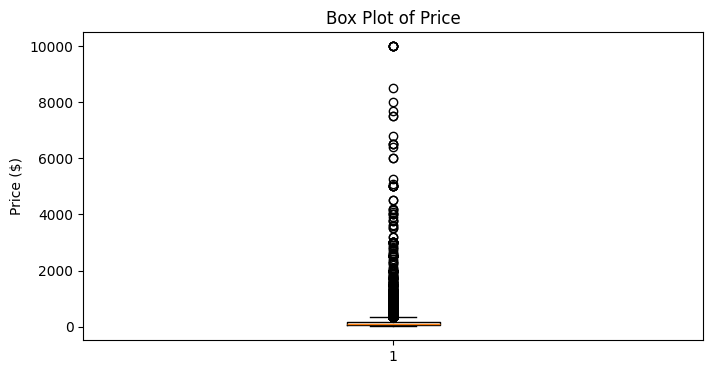

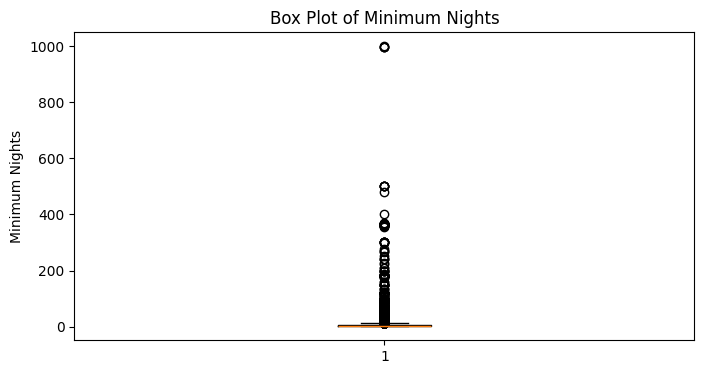

In [ ]:
# TODO: Plot box plots for outlier detection

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(df["price"])
plt.title("Box Plot of Price")
plt.ylabel("Price ($)")
plt.show()

plt.figure(figsize=(8, 4))
plt.boxplot(df["minimum_nights"])
plt.title("Box Plot of Minimum Nights")
plt.ylabel("Minimum Nights")
plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

**Price:** A 0 price is likely a data error, while $10,000 may represent a genuine luxury listing. Remove zero-price listings but retain high prices unless other evidence indicates an error.

**Minimum Nights:** Requirements exceeding three years, such as 1,250 nights, are likely unrealistic. Investigate these records before deciding whether to remove or correct them.



In [ ]:
# TODO: Apply treatment consistent with your judgment above

# Remove listings with zero or negative prices
df = df[df["price"] > 0]

# Remove listings with minimum-night requirements exceeding three years
df = df[df["minimum_nights"] <= 1095]

display(df[["price", "minimum_nights"]].describe())

,price,minimum_nights
count,48883.000000,48883.000000
mean,152.754495,7.004460
std,240.172685,19.726963
min,10.000000,1.000000
25%,69.000000,1.000000
50%,106.000000,3.000000
75%,175.000000,5.000000
max,10000.000000,1000.000000


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# TODO: Encode categorical columns appropriately

df = pd.get_dummies(
    df,
    columns=["neighbourhood_group", "neighbourhood", "room_type"],
    drop_first=True,
    dtype=int
)

In [ ]:
# TODO: Engineer at least two new features

# Calculate price per minimum night
df["price_per_minimum_night"] = (
    df["price"] / df["minimum_nights"]
)

# Create a feature indicating whether the listing has reviews
df["has_reviews"] = (
    df["number_of_reviews"] > 0
).astype(int)

display(df[[
    "price",
    "minimum_nights",
    "price_per_minimum_night",
    "number_of_reviews",
    "has_reviews"
]].head())

,price,minimum_nights,price_per_minimum_night,number_of_reviews,has_reviews
0,149,1,149.0,9,1
1,225,1,225.0,45,1
2,150,3,50.0,0,0
3,89,1,89.0,270,1
4,80,10,8.0,9,1


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

**Feature 1: `price_per_minimum_night`**
This feature represents the nightly price relative to the minimum number of nights required. However, since it is calculated using `price`, the target variable, it should **not be used to predict price** because it would cause data leakage.

**Feature 2: `has_reviews`**
This feature indicates whether a listing has received reviews. It may provide information about a listing's popularity and history. However, it may not be available for newly created listings, so its usefulness for predicting prices for new listings may be limited.

**Columns that should not be used to predict price:**
The `price_per_minimum_night` feature should be excluded because it directly uses the target variable, `price`, in its calculation. The `id` column should also be excluded because it is only a listing identifier and does not represent meaningful property characteristics. Columns such as `number_of_reviews` and `reviews_per_month` should be considered carefully because they may contain information unavailable when predicting prices for new listings.


---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
# TODO: Train/test split (before fitting anything)

from sklearn.model_selection import train_test_split

# Remove target leakage and identifier columns
df = df.drop(
    columns=["price_per_minimum_night", "id"],
    errors="ignore"
)

# Separate features and target
X = df.drop(columns=["price"])
y = df["price"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (39106, 238)
Testing data: (9777, 238)


In [ ]:
# TODO: Build Pipeline combining cleaning, imputation, encoding, and scaling steps

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Select numerical and categorical columns
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Create the final pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor)
])

# Fit only on training data and transform both sets
X_train_processed = pipeline.fit_transform(X_train)
X_test_processed = pipeline.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (39106, 50377)
Processed testing data: (9777, 50377)


---
## Part 6 — Written Reflection
### 1
During the data check we found some problems like wrong prices and missing values. There were 11 listings with prices of $0 or less so we removed them. We also found some listings with a minimum stay of more than 1000 nights. We limited these values to 1095 days to avoid problems when training the model.

Some properties had no reviews so the `reviews_per_month` column was empty. We filled these empty values with 0 because those properties had no monthly reviews. If we had deleted all rows with missing values then we would have lost around 20% of our data. By fixing these problems we were able to keep more data and make the model more reliable.
### 2
Using a pipeline makes the work easier and helps avoid mistakes. If we prepare the full dataset before splitting it into training and testing data then the model may get information from the test data. This can affect the final results. A pipeline helps prevent this problem by keeping the steps organized.

It also saves time because we do not have to repeat each step manually. We can handle missing values and prepare the data in one place. When we use new data later we can apply the same steps again. This makes the code easier to use and maintain.
### 3
Choosing the right model helped us save a lot of time. After converting the neighborhood names into numbers our dataset had more than 230 features. We first tried using `RandomForestRegressor` but it was too slow and caused problems in the notebook.

Then we switched to `Ridge` regression which trained in less than a second. It was much faster and easier to use. It also helps reduce overfitting which means the model is less likely to depend too much on the training data. However we still need to test it with new data to check how well it works.